In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

In [2]:
digits = load_digits()

X = digits.data
y = digits.target

print("Dataset loaded successfully!")

print("Total images:", len(X))
print("Image size:", digits.images[0].shape)
print("Number of features:", X.shape[1])
print("Number of classes:", len(np.unique(y)))

Dataset loaded successfully!
Total images: 1797
Image size: (8, 8)
Number of features: 64
Number of classes: 10


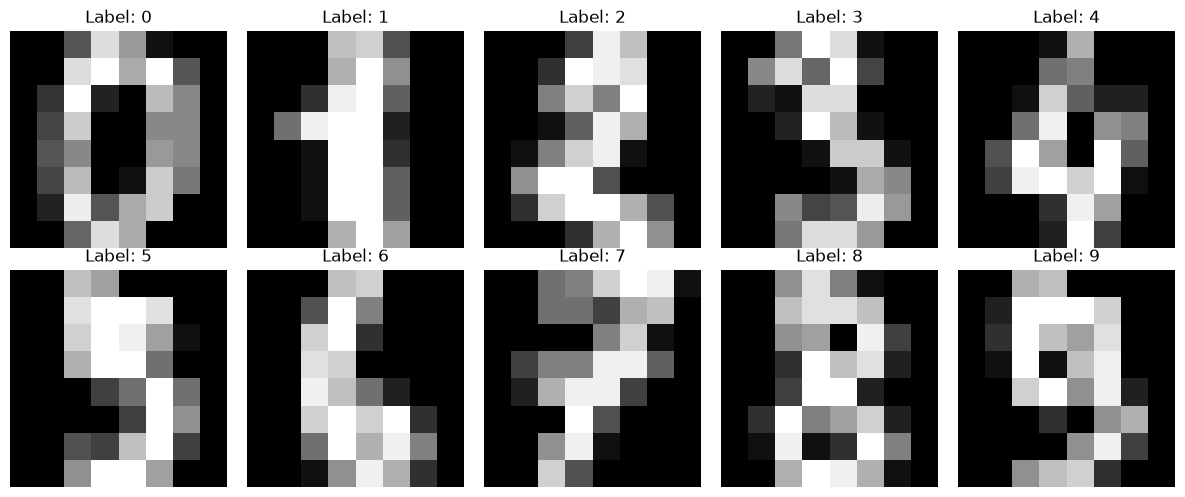

In [3]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(digits.images[i], cmap='gray')
    plt.title(f"Label: {digits.target[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [4]:
print("Features shape:", X.shape)
print("Labels shape:", y.shape)

print("\nUnique digit classes:")
print(np.unique(y))

print("\nFirst 10 labels:")
print(y[:10])

Features shape: (1797, 64)
Labels shape: (1797,)

Unique digit classes:
[0 1 2 3 4 5 6 7 8 9]

First 10 labels:
[0 1 2 3 4 5 6 7 8 9]


In [5]:
X = X / 16.0

print("Normalized data:")
print(X[:5])

Normalized data:
[[0.     0.     0.3125 0.8125 0.5625 0.0625 0.     0.     0.     0.
  0.8125 0.9375 0.625  0.9375 0.3125 0.     0.     0.1875 0.9375 0.125
  0.     0.6875 0.5    0.     0.     0.25   0.75   0.     0.     0.5
  0.5    0.     0.     0.3125 0.5    0.     0.     0.5625 0.5    0.
  0.     0.25   0.6875 0.     0.0625 0.75   0.4375 0.     0.     0.125
  0.875  0.3125 0.625  0.75   0.     0.     0.     0.     0.375  0.8125
  0.625  0.     0.     0.    ]
 [0.     0.     0.     0.75   0.8125 0.3125 0.     0.     0.     0.
  0.     0.6875 1.     0.5625 0.     0.     0.     0.     0.1875 0.9375
  1.     0.375  0.     0.     0.     0.4375 0.9375 1.     1.     0.125
  0.     0.     0.     0.     0.0625 1.     1.     0.1875 0.     0.
  0.     0.     0.0625 1.     1.     0.375  0.     0.     0.     0.
  0.0625 1.     1.     0.375  0.     0.     0.     0.     0.     0.6875
  1.     0.625  0.     0.    ]
 [0.     0.     0.     0.25   0.9375 0.75   0.     0.     0.     0.
  0.1875 1.    

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1437, 64)
Testing data: (360, 64)


In [7]:
svm_model = SVC(
    kernel='rbf',
    C=10,
    gamma='scale'
)

svm_model.fit(X_train, y_train)

print("SVM model trained successfully!")

SVM model trained successfully!


In [8]:
y_pred = svm_model.predict(X_test)

print("Actual labels:")
print(y_test[:20])

print("\nPredicted labels:")
print(y_pred[:20])

Actual labels:
[5 2 8 1 7 2 6 2 6 5 0 5 9 3 4 4 2 4 9 9]

Predicted labels:
[5 2 8 1 7 2 6 2 6 5 0 5 9 3 4 4 2 4 9 9]


In [9]:
accuracy = accuracy_score(y_test, y_pred)

print("SVM Classification Accuracy:",
      accuracy * 100, "%")

SVM Classification Accuracy: 99.44444444444444 %


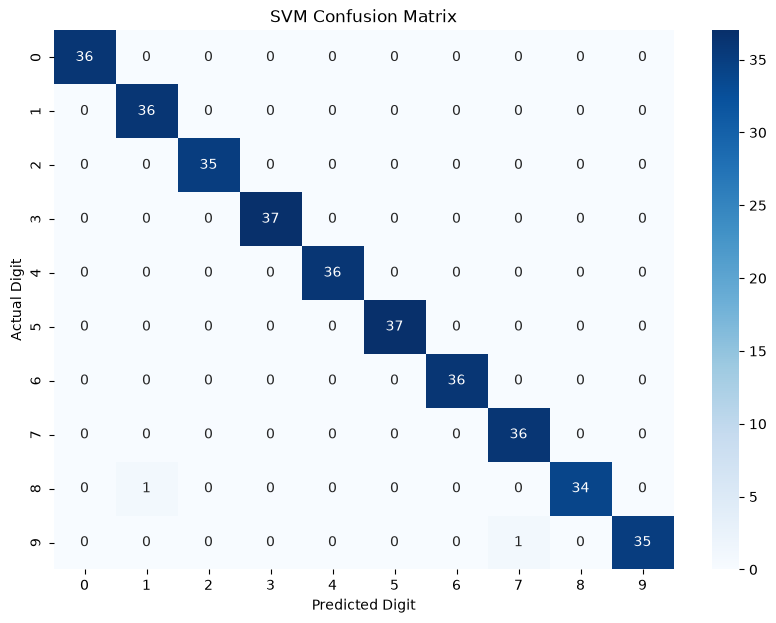

In [10]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=np.arange(10),
    yticklabels=np.arange(10)
)

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("SVM Confusion Matrix")

plt.show()

In [11]:
print("Classification Report:\n")

print(classification_report(y_test, y_pred))

Classification Report:

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.97      1.00      0.99        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       1.00      1.00      1.00        36
           5       1.00      1.00      1.00        37
           6       1.00      1.00      1.00        36
           7       0.97      1.00      0.99        36
           8       1.00      0.97      0.99        35
           9       1.00      0.97      0.99        36

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



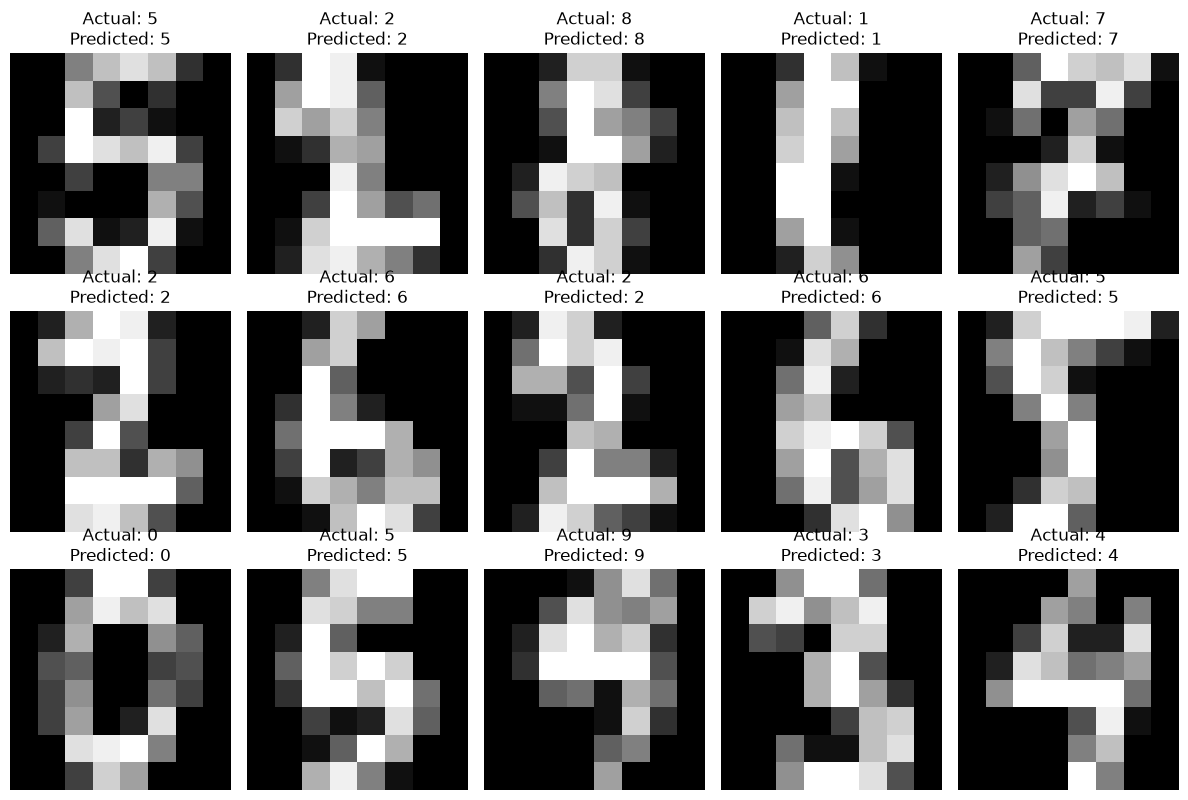

In [12]:
plt.figure(figsize=(12, 8))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(
        X_test[i].reshape(8, 8),
        cmap='gray'
    )

    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {y_pred[i]}"
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

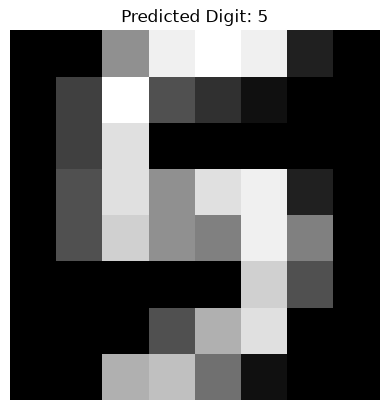

Actual Digit: 5
Predicted Digit: 5


In [13]:
index = 25

sample = X_test[index].reshape(1, -1)

prediction = svm_model.predict(sample)

plt.imshow(
    X_test[index].reshape(8, 8),
    cmap='gray'
)

plt.title(f"Predicted Digit: {prediction[0]}")
plt.axis('off')
plt.show()

print("Actual Digit:", y_test[index])
print("Predicted Digit:", prediction[0])

In [14]:
kernels = ['linear', 'poly', 'rbf']

results = {}

for kernel in kernels:

    model = SVC(kernel=kernel, C=10)

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    acc = accuracy_score(y_test, predictions)

    results[kernel] = acc * 100

print("SVM Kernel Comparison:")

for kernel, accuracy_value in results.items():
    print(kernel, ":", round(accuracy_value, 2), "%")

SVM Kernel Comparison:
linear : 97.78 %
poly : 98.61 %
rbf : 99.44 %


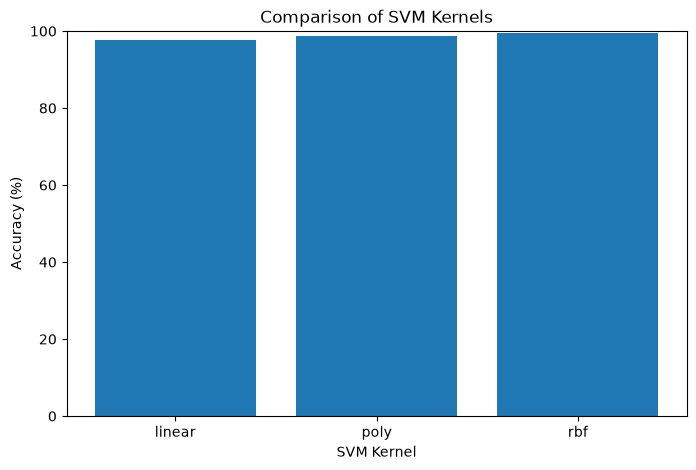

In [15]:
plt.figure(figsize=(8, 5))

plt.bar(
    results.keys(),
    results.values()
)

plt.xlabel("SVM Kernel")
plt.ylabel("Accuracy (%)")
plt.title("Comparison of SVM Kernels")

plt.ylim(0, 100)
plt.show()

Implementation of Support Vector Machines (SVM) for classifying images of handwritten digits into their respective numerical classes (0 to 9). .give me cell by cell code